# Segmentação de clientes com clustering: perfis de compra no e-commerce da Olist

# Contents <a id='back'></a>

* [Introdução](#intro)
* [Etapa 1. Carregando os dados](#data_review)
* [Etapa 2. Construindo o perfil de cada cliente](#features)
* [Etapa 3. Análise exploratória das variáveis](#eda)
* [Etapa 4. Preparando os dados para o clustering](#preparation)
* [Etapa 5. Escolhendo o número de grupos](#k)
* [Etapa 6. Criando e validando os segmentos](#model)
* [Etapa 7. Entendendo cada segmento](#profiles)
* [Etapa 8. Regras simples para identificar os segmentos](#rules)
* [Etapa 9. Clustering x RFM: o que a segmentação acrescenta](#rfm)
* [Etapa 10. Plano de ação por segmento](#actions)
* [Conclusão geral](#end)

## Introdução <a id='intro'></a>

No [Projeto 20](https://github.com/gabrieldeoliver1/Projetos/tree/main/Projeto_20), analisei o e-commerce da Olist com SQL e criei uma segmentação **RFM** com regras definidas por mim (recência, frequência e valor). Essa abordagem é útil, mas tem dois limites: usa só três dimensões e depende de cortes escolhidos à mão.

Neste projeto, uso **clustering**, uma técnica de aprendizado **não supervisionado**, para deixar que os próprios dados revelem grupos de clientes com comportamentos parecidos, considerando também **como** cada cliente compra: quanto gasta por pedido, quanto paga de frete, se parcela, quanto tempo esperou pela entrega e que nota deu.

### Objetivo
- Construir um perfil de comportamento para cada cliente
- Agrupar os clientes com **K-means**, escolhendo o número de grupos com critérios técnicos e de negócio
- Validar a **estabilidade** dos grupos
- Traduzir cada grupo em uma **persona** com nome, características e ação de marketing
- Criar **regras simples** para que a área de negócio identifique os segmentos sem precisar do modelo

### Dados
A mesma base pública do Projeto 20: *Brazilian E-Commerce Public Dataset by Olist*, com cerca de 100 mil pedidos reais entre 2016 e 2018, licença CC BY-NC-SA 4.0.

[Voltar ao Índice](#back)

## Etapa 1. Carregando os dados <a id='data_review'></a>

Se estiver usando o Google Colab ou outro Jupyter online, as bibliotecas abaixo já costumam estar instaladas.

In [1]:
# Instalação das bibliotecas (só é necessário se alguma não estiver instalada)
# %pip install pandas numpy matplotlib seaborn scikit-learn

In [2]:
# Importa as bibliotecas necessárias
import os  # Utilizada para verificar arquivos e pastas
import urllib.request  # Utilizada para baixar os dados
import warnings  # Utilizada para esconder avisos que não afetam o resultado
import zipfile  # Utilizada para descompactar os dados

import numpy as np  # Utilizada para operações numéricas
import pandas as pd  # Utilizada para manipulação de dados
import matplotlib.pyplot as plt  # Utilizada para a construção de gráficos
import matplotlib.ticker as mtick  # Utilizada para formatar os eixos
import seaborn as sns  # Utilizada para gráficos estatísticos
from sklearn.preprocessing import StandardScaler  # Coloca as variáveis na mesma escala
from sklearn.cluster import KMeans  # Algoritmo de clustering
from sklearn.decomposition import PCA  # Reduz as variáveis a 2 dimensões para visualização
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score  # Qualidade dos grupos
from sklearn.tree import DecisionTreeClassifier, export_text  # Regras simples para descrever os grupos

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
AZUL, LARANJA, CINZA, VERMELHO = "#1f4e79", "#e07b00", "#9aa5b1", "#c0392b"
SEMENTE = 42  # Semente para resultados reproduzíveis
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [3]:
# Baixa os dados do Projeto 20, se ainda não estiverem na pasta, e descompacta
ARQUIVO_ZIP = "olist.zip"
URL_GITHUB = "https://raw.githubusercontent.com/gabrieldeoliver1/Projetos/main/Projeto_20/olist.zip"
if not os.path.exists(ARQUIVO_ZIP):
    print("Baixando os dados do GitHub (cerca de 29 MB)...")
    urllib.request.urlretrieve(URL_GITHUB, ARQUIVO_ZIP)
with zipfile.ZipFile(ARQUIVO_ZIP) as z:
    z.extractall("dados_olist")


def ler(nome):
    """Lê uma das tabelas da Olist."""
    return pd.read_csv(f"dados_olist/olist_{nome}_dataset.csv")


pedidos, itens, clientes = ler("orders"), ler("order_items"), ler("customers")
pagamentos, avaliacoes, produtos = ler("order_payments"), ler("order_reviews"), ler("products")

# Mantém só os pedidos entregues, que são vendas concretizadas
pedidos = pedidos[pedidos["order_status"] == "delivered"].copy()
for coluna in ["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]:
    pedidos[coluna] = pd.to_datetime(pedidos[coluna])
print(f"Pedidos entregues: {len(pedidos):,}".replace(",", "."))

Pedidos entregues: 96.478


[Voltar ao Índice](#back)

## Etapa 2. Construindo o perfil de cada cliente <a id='features'></a>

O clustering agrupa **clientes**, então preciso de uma linha por cliente (`customer_unique_id`). Para cada um, calculo variáveis que descrevem **quanto**, **como** e **com que experiência** ele comprou:

| Variável | O que mede | Por que importa |
|---|---|---|
| `recencia_dias` | Dias desde a última compra | Clientes recentes respondem melhor a ações |
| `valor_total` | Total gasto (produtos + frete) | Valor do cliente para o negócio |
| `ticket_medio` | Valor médio por pedido | Perfil de gasto |
| `itens_por_pedido` | Média de itens em cada pedido | Compra de um item só ou "cesta" |
| `frete_pct` | Frete como % do preço dos produtos | Sensibilidade ao custo de entrega |
| `parcelas_media` | Média de parcelas no pagamento | Uso do crédito para comprar |
| `dias_entrega` | Tempo médio de entrega, em dias | Experiência logística |
| `nota_media` | Nota média dada nas avaliações | Satisfação |

A **frequência** não entra no clustering: como 97% dos clientes compraram uma única vez, ela quase não varia e não ajuda a separar os grupos. Ela será usada só para descrever os segmentos.

In [4]:
# Liga cada pedido ao cliente único
base = pedidos.merge(clientes[["customer_id", "customer_unique_id", "customer_state"]], on="customer_id")

# Valor, frete e quantidade de itens de cada pedido
valores_pedido = itens.groupby("order_id").agg(preco=("price", "sum"), frete=("freight_value", "sum"),
                                               itens=("order_item_id", "count")).reset_index()
# Parcelas de cada pedido (pagamentos sem cartão contam como 1 parcela)
parcelas_pedido = pagamentos.groupby("order_id")["payment_installments"].max().clip(lower=1).rename("parcelas").reset_index()
# Nota média de cada pedido (alguns pedidos têm mais de uma avaliação)
nota_pedido = avaliacoes.groupby("order_id")["review_score"].mean().rename("nota").reset_index()

base = (base.merge(valores_pedido, on="order_id").merge(parcelas_pedido, on="order_id", how="left")
            .merge(nota_pedido, on="order_id", how="left"))
base["dias_entrega"] = (base["order_delivered_customer_date"] - base["order_purchase_timestamp"]).dt.days
base["valor"] = base["preco"] + base["frete"]
print(f"Pedidos com todas as informações: {len(base):,}".replace(",", "."))

Pedidos com todas as informações: 96.478


In [5]:
# Data de referência: o dia seguinte à última compra da base
data_ref = base["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

# Agrega por cliente: uma linha para cada pessoa
perfil = base.groupby("customer_unique_id").agg(
    ultima_compra=("order_purchase_timestamp", "max"),
    pedidos=("order_id", "nunique"),
    valor_total=("valor", "sum"),
    preco_total=("preco", "sum"),
    frete_total=("frete", "sum"),
    itens=("itens", "sum"),
    parcelas_media=("parcelas", "mean"),
    dias_entrega=("dias_entrega", "mean"),
    nota_media=("nota", "mean"),
    uf=("customer_state", "first"),
)
perfil["recencia_dias"] = (data_ref - perfil["ultima_compra"]).dt.days
perfil["ticket_medio"] = perfil["valor_total"] / perfil["pedidos"]
perfil["itens_por_pedido"] = perfil["itens"] / perfil["pedidos"]
perfil["frete_pct"] = perfil["frete_total"] / perfil["preco_total"] * 100

VARIAVEIS = ["recencia_dias", "valor_total", "ticket_medio", "itens_por_pedido",
             "frete_pct", "parcelas_media", "dias_entrega", "nota_media"]
print(f"Clientes: {len(perfil):,}".replace(",", "."))
perfil[VARIAVEIS].isna().sum()

Clientes: 93.358


recencia_dias         0
valor_total           0
ticket_medio          0
itens_por_pedido      0
frete_pct             0
parcelas_media        1
dias_entrega          8
nota_media          603
dtype: int64

In [6]:
# Preenche os poucos valores ausentes com a mediana de cada variável
for var in ["parcelas_media", "dias_entrega", "nota_media"]:
    perfil[var] = perfil[var].fillna(perfil[var].median())
perfil[VARIAVEIS].describe().T

,count,mean,std,min,25%,50%,75%,max
recencia_dias,"93,358.00",237.94,152.59,1.00,114.00,219.00,346.00,714.00
valor_total,"93,358.00",165.17,226.29,9.59,63.01,107.78,182.51,"13,664.08"
ticket_medio,"93,358.00",160.29,219.55,9.59,62.33,105.63,176.59,"13,664.08"
itens_por_pedido,"93,358.00",1.14,0.53,1.00,1.00,1.00,1.00,21.00
frete_pct,"93,358.00",30.63,30.88,0.00,13.20,22.43,37.83,"2,144.71"
parcelas_media,"93,358.00",2.92,2.69,1.00,1.00,2.00,4.00,24.00
dias_entrega,"93,358.00",12.10,9.55,0.00,6.00,10.00,15.00,209.00
nota_media,"93,358.00",4.16,1.28,1.00,4.00,5.00,5.00,5.00


[Voltar ao Índice](#back)

## Etapa 3. Análise exploratória das variáveis <a id='eda'></a>

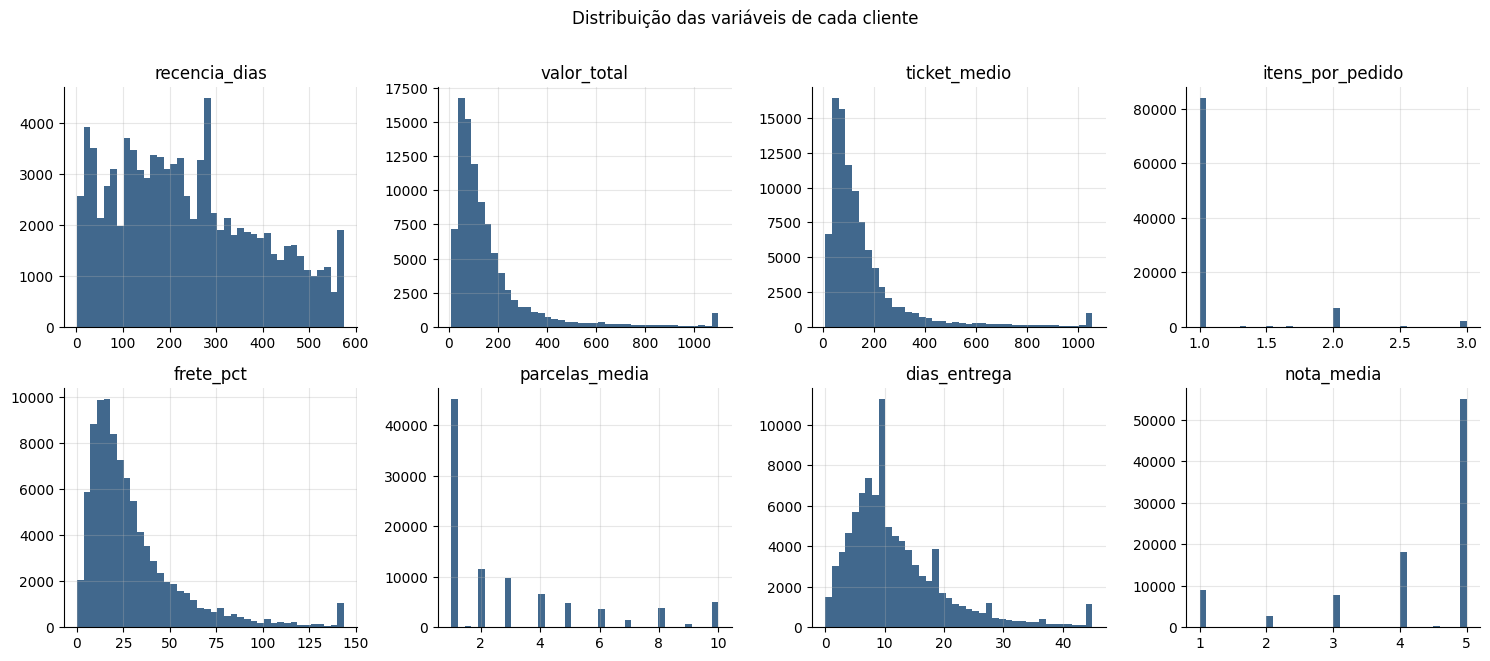

In [7]:
fig, axs = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, var in zip(axs.flat, VARIAVEIS):
    limite = perfil[var].quantile(0.99)  # Corta o 1% mais extremo só para visualizar melhor
    ax.hist(perfil[var].clip(upper=limite), bins=40, color=AZUL, alpha=0.85)
    ax.set_title(var)
plt.suptitle("Distribuição das variáveis de cada cliente", y=1.01)
plt.tight_layout()
plt.show()

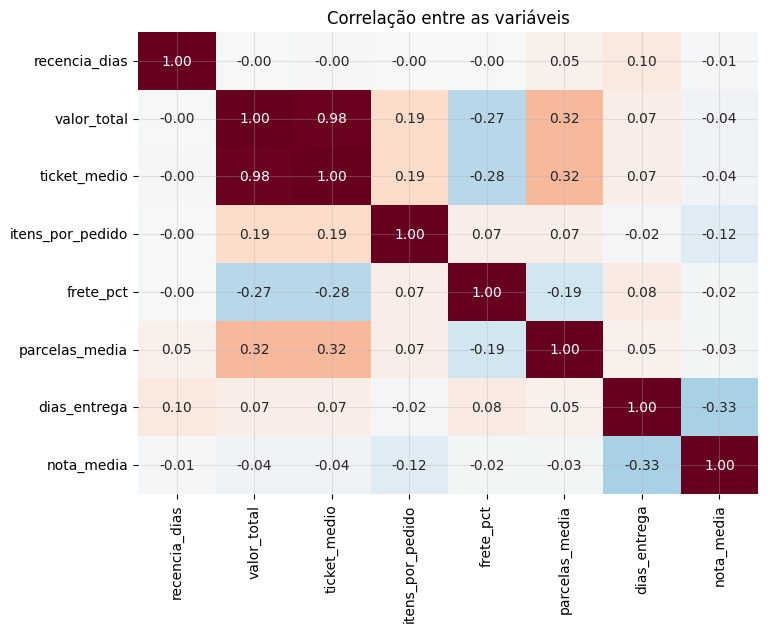

In [8]:
# Correlação entre as variáveis
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(perfil[VARIAVEIS].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, cbar=False)
ax.set_title("Correlação entre as variáveis")
plt.show()

### Conclusões

- **Valor, ticket, frete e prazo de entrega são muito assimétricos**: a maioria dos clientes tem valores baixos, e poucos têm valores muito altos. Isso exige uma transformação antes do clustering.
- A **nota média** se concentra em 5, com um grupo menor de notas baixas.
- O **valor total** e o **ticket médio** são quase a mesma informação (correlação perto de 1), porque quase todos compraram uma única vez. Mantenho os dois porque, para os clientes que voltam, eles diferenciam quem compra muitas vezes barato de quem compra poucas vezes caro.
- O **prazo de entrega** e a **nota** têm correlação negativa: entregas mais longas, notas menores, o que confirma o achado do Projeto 20.

[Voltar ao Índice](#back)

## Etapa 4. Preparando os dados para o clustering <a id='preparation'></a>

O K-means agrupa os clientes pela **distância** entre eles. Por isso, duas preparações são essenciais:

1. **Reduzir a assimetria:** valores, ticket, frete e prazo têm caudas longas. Aplico o **logaritmo**, que aproxima esses valores e evita que poucos clientes extremos dominem os grupos. Antes, limito os valores ao percentil 1% e 99% (**winsorização**), para conter os extremos.
2. **Padronizar a escala:** sem isso, o valor gasto (centenas de reais) pesaria muito mais que a nota (1 a 5). O `StandardScaler` coloca todas as variáveis com média 0 e desvio padrão 1.

In [9]:
LOG = ["valor_total", "ticket_medio", "itens_por_pedido", "frete_pct", "parcelas_media", "dias_entrega"]

X = perfil[VARIAVEIS].copy()
for var in VARIAVEIS:
    X[var] = X[var].clip(X[var].quantile(0.01), X[var].quantile(0.99))  # Winsorização
for var in LOG:
    X[var] = np.log1p(X[var])  # log(1 + x), que funciona também quando x = 0

escalonador = StandardScaler()
X_esc = escalonador.fit_transform(X)
pd.DataFrame(X_esc, columns=VARIAVEIS).describe().loc[["mean", "std"]].round(2)

,recencia_dias,valor_total,ticket_medio,itens_por_pedido,frete_pct,parcelas_media,dias_entrega,nota_media
mean,0.00,0.00,0.00,0.00,-0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


[Voltar ao Índice](#back)

## Etapa 5. Escolhendo o número de grupos <a id='k'></a>

O K-means precisa que eu informe o número de grupos (**k**). Testo de 2 a 10 grupos e comparo três critérios:

- **Método do cotovelo (inércia):** a soma das distâncias de cada cliente ao centro do seu grupo. Ela sempre cai com mais grupos; procuro o ponto em que a queda perde força.
- **Silhouette:** mede se cada cliente está mais perto do seu grupo do que do grupo vizinho. Vai de -1 a 1; quanto maior, melhor.
- **Davies-Bouldin:** compara a dispersão dentro dos grupos com a distância entre eles. Quanto **menor**, melhor.

Como o silhouette é pesado de calcular em 93 mil clientes, uso uma amostra de 10 mil.

O critério final, porém, é de **negócio**: os grupos precisam ser distintos o bastante para justificar ações diferentes e poucos o bastante para a equipe de marketing conseguir operar.

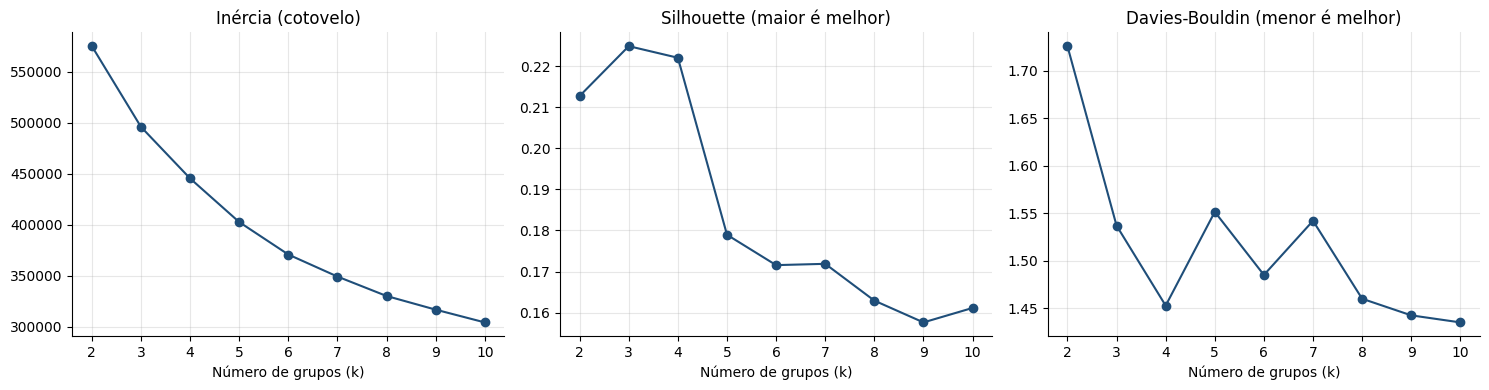

,inercia,silhouette,davies_bouldin
k,,,
2,"575,041.51",0.21,1.73
3,"495,952.58",0.23,1.54
4,"445,488.52",0.22,1.45
5,"402,769.22",0.18,1.55
6,"370,970.05",0.17,1.49
7,"349,393.96",0.17,1.54
8,"330,360.65",0.16,1.46
9,"316,986.29",0.16,1.44
10,"304,486.80",0.16,1.44


In [10]:
amostra = np.random.default_rng(SEMENTE).choice(len(X_esc), 10_000, replace=False)
metricas = []
for k in range(2, 11):
    modelo = KMeans(n_clusters=k, n_init=10, random_state=SEMENTE).fit(X_esc)
    metricas.append({
        "k": k,
        "inercia": modelo.inertia_,
        "silhouette": silhouette_score(X_esc[amostra], modelo.labels_[amostra]),
        "davies_bouldin": davies_bouldin_score(X_esc, modelo.labels_),
    })
metricas = pd.DataFrame(metricas).set_index("k")

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, coluna, titulo in zip(axs, metricas.columns, ["Inércia (cotovelo)", "Silhouette (maior é melhor)",
                                                      "Davies-Bouldin (menor é melhor)"]):
    ax.plot(metricas.index, metricas[coluna], marker="o", color=AZUL)
    ax.set_title(titulo)
    ax.set_xlabel("Número de grupos (k)")
plt.tight_layout()
plt.show()
metricas.round(3)

### Estabilidade de cada opção

As métricas acima ficam próximas entre si, como é comum em dados reais de comportamento. Um critério decisivo é a **estabilidade**: rodo o K-means com 5 sementes diferentes para cada k e comparo os grupos com o **índice de Rand ajustado (ARI)**. Um ARI perto de 1 significa que os grupos se repetem; um ARI baixo indica que a divisão depende do acaso e não seria confiável para o negócio.

In [11]:
estabilidade = {}
for k in range(3, 8):
    referencia = KMeans(n_clusters=k, n_init=5, random_state=0).fit_predict(X_esc)
    aris = [adjusted_rand_score(referencia, KMeans(n_clusters=k, n_init=5, random_state=s).fit_predict(X_esc))
            for s in range(1, 5)]
    estabilidade[k] = {"ARI médio": np.mean(aris), "ARI mínimo": np.min(aris)}
pd.DataFrame(estabilidade).T.round(3)

,ARI médio,ARI mínimo
3,1.00,1.00
4,0.68,0.36
5,0.99,0.98
6,0.96,0.92
7,0.65,0.55


### Conclusões: escolha de k = 5

- O **silhouette** é baixo para todos os valores de k (entre 0,16 e 0,23), o que é comum em dados de comportamento: os clientes formam um contínuo, sem fronteiras nítidas. Os grupos ainda são úteis para o negócio, mas é importante saber que são **tendências**, não categorias rígidas.
- **k = 4 e k = 7 são instáveis** (ARI médio de 0,68 e 0,65): a divisão muda dependendo da semente, então não serviriam para decisões.
- **k = 3 é o mais estável e tem o melhor silhouette**, mas junta perfis que pedem ações diferentes.
- **k = 5 é praticamente tão estável quanto k = 3** (ARI de 0,99) e separa perfis com ações claras, como os clientes **insatisfeitos com a entrega** e os que compram **vários itens por pedido**.

Por isso, escolho **k = 5**: o equilíbrio entre estabilidade, qualidade técnica e utilidade para o negócio.

[Voltar ao Índice](#back)

## Etapa 6. Criando e validando os segmentos <a id='model'></a>

In [12]:
K = 5  # Número de grupos escolhido na etapa anterior
kmeans = KMeans(n_clusters=K, n_init=20, random_state=SEMENTE).fit(X_esc)

# Numera os grupos de forma estável, do menor para o maior valor gasto médio
ordem = perfil.assign(grupo=kmeans.labels_).groupby("grupo")["valor_total"].mean().sort_values().index
renumeracao = {antigo: novo for novo, antigo in enumerate(ordem)}
perfil["grupo"] = pd.Series(kmeans.labels_, index=perfil.index).map(renumeracao)
perfil["grupo"].value_counts().sort_index()

grupo
0    27417
1    10576
2    32186
3     8756
4    14423
Name: count, dtype: int64

### Os grupos são estáveis?

Um bom segmento não pode mudar a cada execução. Para testar, rodo o K-means 10 vezes com sementes diferentes e comparo com o resultado original usando o **índice de Rand ajustado (ARI)**: 1 significa grupos idênticos, e 0, concordância de acaso.

In [13]:
ari = [adjusted_rand_score(perfil["grupo"], KMeans(n_clusters=K, n_init=5, random_state=s).fit_predict(X_esc))
       for s in range(1, 11)]
print(f"ARI médio entre execuções: {np.mean(ari):.3f} (mínimo de {np.min(ari):.3f})")

ARI médio entre execuções: 0.970 (mínimo de 0.958)


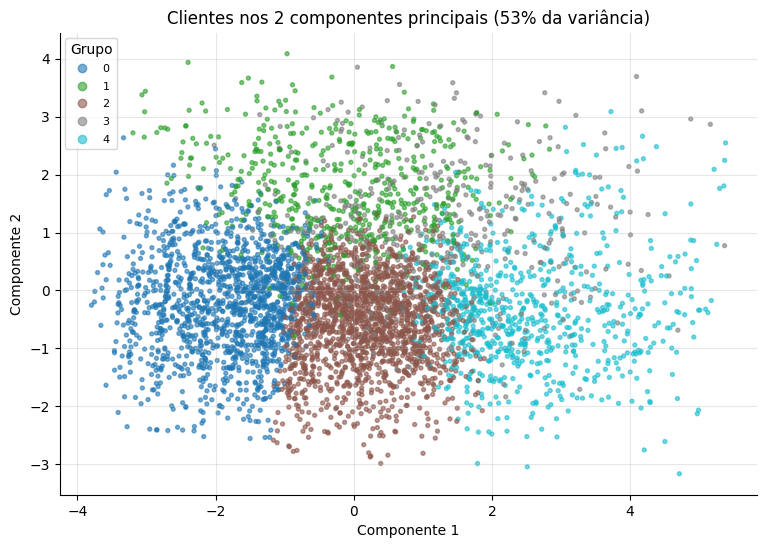

In [14]:
# Visualização dos grupos em 2 dimensões com PCA (amostra de 5 mil clientes)
pca = PCA(n_components=2, random_state=SEMENTE)
coords = pca.fit_transform(X_esc)
idx = np.random.default_rng(SEMENTE).choice(len(coords), 5000, replace=False)
fig, ax = plt.subplots(figsize=(9, 6))
dispersao = ax.scatter(coords[idx, 0], coords[idx, 1], c=perfil["grupo"].values[idx], cmap="tab10", s=8, alpha=0.6)
ax.legend(*dispersao.legend_elements(), title="Grupo", loc="best", fontsize=8)
ax.set_title(f"Clientes nos 2 componentes principais ({pca.explained_variance_ratio_.sum():.0%} da variância)")
ax.set_xlabel("Componente 1")
ax.set_ylabel("Componente 2")
plt.show()

### Conclusões

- Os segmentos são **estáveis**: o ARI médio entre execuções com sementes diferentes é de **0,97**.
- No gráfico de PCA, que resume as 8 variáveis em 2 dimensões (53% da informação), os grupos aparecem como regiões distintas, mas com sobreposição nas bordas, o que é coerente com o silhouette moderado.

[Voltar ao Índice](#back)

## Etapa 7. Entendendo cada segmento <a id='profiles'></a>

Agora o mais importante: **o que caracteriza cada grupo?** Comparo a média de cada variável no grupo com a média geral. O mapa de calor mostra, em desvios padrão, quanto cada grupo está acima (vermelho) ou abaixo (azul) da média.

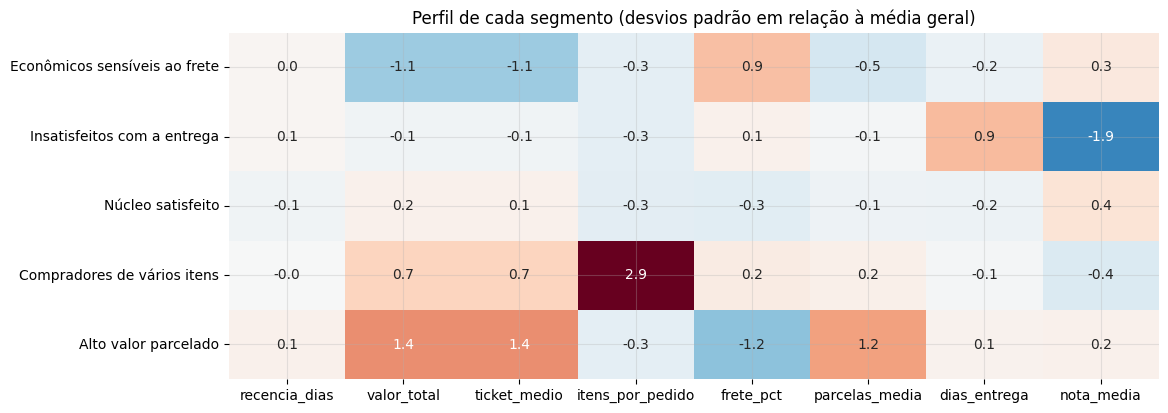

In [15]:
NOMES = {0: "Econômicos sensíveis ao frete", 1: "Insatisfeitos com a entrega", 2: "Núcleo satisfeito", 3: "Compradores de vários itens", 4: "Alto valor parcelado"}  # Nomes definidos a partir dos perfis abaixo
perfil["segmento"] = perfil["grupo"].map(NOMES)

# Perfil padronizado: média de cada variável no grupo, em desvios padrão em relação à média geral
padronizado = pd.DataFrame(X_esc, columns=VARIAVEIS, index=perfil.index).groupby(perfil["segmento"]).mean()
padronizado = padronizado.loc[[NOMES[g] for g in sorted(NOMES)]]
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(padronizado, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax, cbar=False)
ax.set_title("Perfil de cada segmento (desvios padrão em relação à média geral)")
ax.set_ylabel("")
plt.show()

In [16]:
# Perfil em valores reais: fácil de ler para a área de negócio
total_receita = perfil["valor_total"].sum()
resumo = perfil.groupby("segmento").agg(
    clientes=("grupo", "size"),
    valor_total=("valor_total", "median"),
    ticket_medio=("ticket_medio", "median"),
    itens_por_pedido=("itens_por_pedido", "mean"),
    frete_pct=("frete_pct", "median"),
    parcelas=("parcelas_media", "mean"),
    dias_entrega=("dias_entrega", "median"),
    nota_media=("nota_media", "mean"),
    recencia_dias=("recencia_dias", "median"),
    recompra_pct=("pedidos", lambda s: (s > 1).mean() * 100),
)
resumo.insert(1, "pct_clientes", resumo["clientes"] / len(perfil) * 100)
resumo.insert(2, "pct_receita", perfil.groupby("segmento")["valor_total"].sum() / total_receita * 100)
resumo = resumo.loc[[NOMES[g] for g in sorted(NOMES)]]
resumo.round(1)

,clientes,pct_clientes,pct_receita,valor_total,ticket_medio,itens_por_pedido,frete_pct,parcelas,dias_entrega,nota_media,recencia_dias,recompra_pct
segmento,,,,,,,,,,,,
Econômicos sensíveis ao frete,27417,29.40,9.10,48.90,48.30,1.00,42.30,1.60,9.00,4.60,227.00,1.50
Insatisfeitos com a entrega,10576,11.30,8.10,100.40,98.50,1.00,24.50,2.70,19.00,1.70,220.00,2.50
Núcleo satisfeito,32186,34.50,28.30,122.90,119.30,1.00,17.10,2.40,9.00,4.70,199.00,3.60
Compradores de vários itens,8756,9.40,14.30,178.50,173.80,2.40,27.10,3.50,9.00,3.60,217.00,3.90
Alto valor parcelado,14423,15.40,40.30,309.20,296.40,1.00,8.20,6.30,11.00,4.40,252.00,4.40


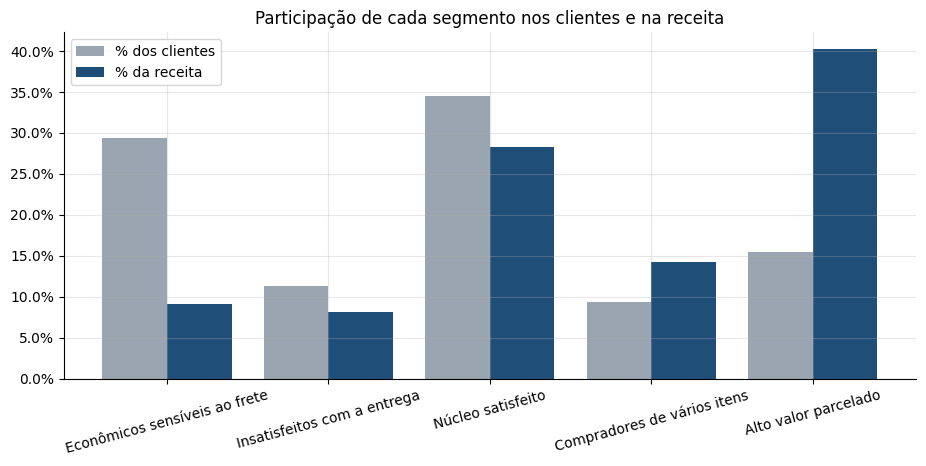

In [17]:
# Clientes x receita por segmento
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(resumo))
ax.bar(x - 0.2, resumo["pct_clientes"], 0.4, color=CINZA, label="% dos clientes")
ax.bar(x + 0.2, resumo["pct_receita"], 0.4, color=AZUL, label="% da receita")
ax.set_xticks(x)
ax.set_xticklabels(resumo.index, rotation=15)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Participação de cada segmento nos clientes e na receita")
ax.legend()
plt.show()

In [18]:
# Região dos clientes e categorias mais compradas em cada segmento
REGIAO = {"SP": "Sudeste", "RJ": "Sudeste", "MG": "Sudeste", "ES": "Sudeste", "PR": "Sul", "SC": "Sul", "RS": "Sul",
          "DF": "Centro-Oeste", "GO": "Centro-Oeste", "MT": "Centro-Oeste", "MS": "Centro-Oeste"}
perfil["regiao"] = perfil["uf"].map(REGIAO).fillna("Norte/Nordeste")
regioes = pd.crosstab(perfil["segmento"], perfil["regiao"], normalize="index") * 100
print("Distribuição por região (%):")
print(regioes.loc[resumo.index].round(1).to_string())

categorias = (itens.merge(produtos[["product_id", "product_category_name"]], on="product_id")
                   .merge(base[["order_id", "customer_unique_id"]].drop_duplicates(), on="order_id")
                   .merge(perfil[["segmento"]], left_on="customer_unique_id", right_index=True))
print("\nTrês categorias com mais itens comprados em cada segmento:")
for segmento in resumo.index:
    top = categorias[categorias["segmento"] == segmento]["product_category_name"].value_counts(normalize=True).head(3)
    print(f"  {segmento}: " + ", ".join(f"{c} ({p:.0%})" for c, p in top.items()))

Distribuição por região (%):
regiao                         Centro-Oeste  Norte/Nordeste  Sudeste   Sul
segmento                                                                  
Econômicos sensíveis ao frete          5.40            9.60    70.40 14.60
Insatisfeitos com a entrega            6.50           18.10    61.40 14.00
Núcleo satisfeito                      5.70            9.20    71.10 14.00
Compradores de vários itens            6.20            9.50    69.50 14.80
Alto valor parcelado                   6.20           15.20    64.10 14.40

Três categorias com mais itens comprados em cada segmento:
  Econômicos sensíveis ao frete: telefonia (9%), beleza_saude (8%), utilidades_domesticas (7%)
  Insatisfeitos com a entrega: cama_mesa_banho (12%), beleza_saude (9%), informatica_acessorios (8%)
  Núcleo satisfeito: cama_mesa_banho (10%), beleza_saude (10%), esporte_lazer (9%)
  Compradores de vários itens: moveis_decoracao (14%), cama_mesa_banho (14%), informatica_acessorios (8%)
 

### As 5 personas

| Segmento | % clientes | % receita | Como é |
|---|---|---|---|
| **Alto valor parcelado** | 15% | **40%** | Ticket de R\$ 296, cerca de 6 parcelas, frete de só 8% do preço. Compra relógios, presentes e beleza. Satisfeito (nota 4,4) |
| **Núcleo satisfeito** | 35% | 28% | O cliente típico: ticket de R\$ 119, entrega em 9 dias e a nota mais alta (4,7) |
| **Compradores de vários itens** | 9% | 14% | Leva 2,4 itens por pedido, principalmente móveis, decoração e cama, mesa e banho. Nota abaixo da média (3,6) |
| **Econômicos sensíveis ao frete** | 29% | 9% | Compras pequenas (R\$ 48) e à vista, em que o **frete equivale a 42% do preço**. Satisfeitos (4,6) |
| **Insatisfeitos com a entrega** | 11% | 8% | Nota média de **1,7** e entrega em **19 dias**, o dobro dos demais. Mais concentrados no Norte e no Nordeste (18%) |

Dois achados merecem destaque:

- **15% dos clientes geram 40% da receita**, e eles compram de forma parcelada. O parcelamento é o que viabiliza esse ticket.
- O segmento **Insatisfeitos com a entrega** não é definido pelo que o cliente compra, mas pela **experiência que ele teve**. Ele mostra, com dados, o custo dos atrasos para a relação com o cliente.

[Voltar ao Índice](#back)

## Etapa 8. Regras simples para identificar os segmentos <a id='rules'></a>

O K-means é ótimo para descobrir grupos, mas a equipe de marketing precisa de **regras simples** para usá-los, por exemplo, em uma ferramenta de e-mail ou de CRM. Para isso, treino uma **árvore de decisão** rasa que aprende a reproduzir os segmentos a partir das variáveis originais. Se ela acertar bem, suas regras podem ser usadas no dia a dia.

In [19]:
arvore = DecisionTreeClassifier(max_depth=4, min_samples_leaf=500, random_state=SEMENTE)
arvore.fit(perfil[VARIAVEIS], perfil["segmento"])
print(f"Acerto da árvore ao reproduzir os segmentos: {arvore.score(perfil[VARIAVEIS], perfil['segmento']):.1%}")
print()
print(export_text(arvore, feature_names=VARIAVEIS, decimals=1, max_depth=3))

Acerto da árvore ao reproduzir os segmentos: 84.9%

|--- valor_total <= 77.6
|   |--- nota_media <= 2.2
|   |   |--- dias_entrega <= 7.5
|   |   |   |--- class: Insatisfeitos com a entrega
|   |   |--- dias_entrega >  7.5
|   |   |   |--- ticket_medio <= 37.5
|   |   |   |   |--- class: Insatisfeitos com a entrega
|   |   |   |--- ticket_medio >  37.5
|   |   |   |   |--- class: Insatisfeitos com a entrega
|   |--- nota_media >  2.2
|   |   |--- frete_pct <= 15.6
|   |   |   |--- class: Núcleo satisfeito
|   |   |--- frete_pct >  15.6
|   |   |   |--- ticket_medio <= 67.6
|   |   |   |   |--- class: Econômicos sensíveis ao frete
|   |   |   |--- ticket_medio >  67.6
|   |   |   |   |--- class: Econômicos sensíveis ao frete
|--- valor_total >  77.6
|   |--- itens_por_pedido <= 1.6
|   |   |--- ticket_medio <= 210.2
|   |   |   |--- nota_media <= 3.4
|   |   |   |   |--- class: Insatisfeitos com a entrega
|   |   |   |--- nota_media >  3.4
|   |   |   |   |--- class: Núcleo satisfeito
| 

### Conclusões

A árvore de decisão reproduz os segmentos com **85% de acerto** usando poucas regras, por exemplo:

- **Valor de até R\$ 78 e nota até 2,2:** Insatisfeitos com a entrega
- **Valor de até R\$ 78, nota acima de 2,2 e frete acima de 15,6% do preço:** Econômicos sensíveis ao frete
- **Mais de 1,6 item por pedido:** Compradores de vários itens
- **Ticket acima de R\$ 210 e mais de 2 parcelas:** Alto valor parcelado

Essas regras podem ser configuradas diretamente em uma ferramenta de CRM ou de e-mail marketing, sem depender do modelo.

[Voltar ao Índice](#back)

## Etapa 9. Clustering x RFM: o que a segmentação acrescenta <a id='rfm'></a>

Comparo os novos segmentos com uma segmentação RFM clássica, como a do Projeto 20, para ver se o clustering traz informação nova ou só repete o que as regras de recência e valor já mostravam.

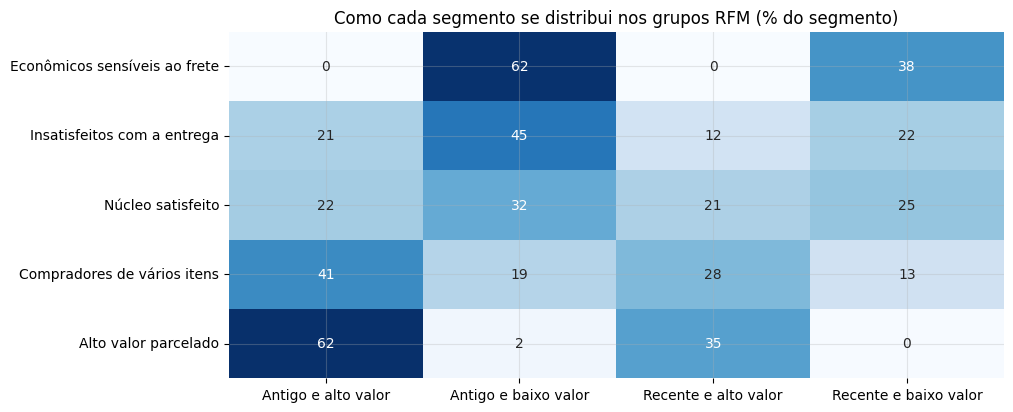

In [20]:
# RFM simplificado: notas de 1 a 5 para recência e valor (5 = melhor)
perfil["nota_r"] = pd.qcut(perfil["recencia_dias"].rank(method="first", ascending=False), 5, labels=False) + 1
perfil["nota_m"] = pd.qcut(perfil["valor_total"].rank(method="first"), 5, labels=False) + 1
perfil["rfm"] = np.select(
    [(perfil.nota_r >= 4) & (perfil.nota_m >= 4), perfil.nota_r >= 4, perfil.nota_m >= 4],
    ["Recente e alto valor", "Recente e baixo valor", "Antigo e alto valor"], default="Antigo e baixo valor")

cruzamento = pd.crosstab(perfil["segmento"], perfil["rfm"], normalize="index") * 100
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(cruzamento.loc[resumo.index], annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar=False)
ax.set_title("Como cada segmento se distribui nos grupos RFM (% do segmento)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.show()

### Conclusões

O clustering **não repete o RFM**, ele acrescenta informação:

- Os **Insatisfeitos com a entrega** estão espalhados por todos os grupos RFM. Uma segmentação baseada só em recência e valor **não enxergaria esses clientes**, que precisam de uma abordagem completamente diferente (recuperar a confiança, e não oferecer mais produtos).
- O **Alto valor parcelado** coincide com os grupos de alto valor do RFM, mas agora sabemos **por que** eles gastam mais: o parcelamento.
- Os **Econômicos sensíveis ao frete** estão todos nos grupos de baixo valor, mas o clustering revela a causa: o frete pesa muito em compras pequenas.

[Voltar ao Índice](#back)

## Etapa 10. Plano de ação por segmento <a id='actions'></a>

| Segmento | Objetivo | Ações recomendadas | Métrica de sucesso |
|---|---|---|---|
| **Alto valor parcelado** | Gerar a segunda compra | Ofertas com parcelamento sem juros em categorias de presente; campanhas em datas comemorativas | Taxa de recompra |
| **Núcleo satisfeito** | Transformar satisfação em recompra | Pedido de avaliação e indicação; cupom para a segunda compra | Recompra e indicações |
| **Compradores de vários itens** | Melhorar a experiência | Revisar embalagem e prazo de pedidos com vários itens; kits de produtos complementares | Nota média e ticket |
| **Econômicos sensíveis ao frete** | Reduzir o peso do frete | Frete grátis acima de um valor mínimo, incentivando um ticket maior | Ticket médio |
| **Insatisfeitos com a entrega** | Recuperar a confiança | Contato proativo, cupom de desculpas e prioridade logística na próxima compra | Nota e recompra |

Todas as ações devem ser validadas com **testes A/B**, como no Projeto 19, antes de ser aplicadas a todos os clientes.

[Voltar ao Índice](#back)

## Conclusão geral <a id='end'></a>

Neste projeto, segmentei **93 mil clientes** da Olist com **K-means**, a partir de 8 variáveis de comportamento de compra.

**Principais resultados:**

- A escolha de **5 segmentos** combinou critérios técnicos (cotovelo, silhouette e Davies-Bouldin) com um teste de **estabilidade**, que descartou as opções de 4 e 7 grupos por mudarem de uma execução para outra. Os segmentos finais são estáveis (ARI de 0,97).
- Os segmentos viraram **5 personas** com ações claras. O mais valioso, **Alto valor parcelado**, tem 15% dos clientes e 40% da receita.
- O clustering encontrou um grupo que a segmentação RFM não enxerga: os **Insatisfeitos com a entrega**, 11% dos clientes, com nota média de 1,7.
- Uma **árvore de decisão** traduziu os segmentos em regras simples, com 85% de acerto, prontas para uso em ferramentas de marketing.

**Limitações e próximos passos:**

- Os grupos são tendências, não fronteiras rígidas (silhouette moderado), o que é natural em dados de comportamento.
- Com 97% de clientes de compra única, a segmentação descreve principalmente a **primeira compra**. Com mais histórico, seria possível incluir frequência e mudança de comportamento ao longo do tempo.
- Testar outros algoritmos, como modelos de mistura gaussiana, e atualizar os segmentos periodicamente.

[Voltar ao Índice](#back)